# Analysis of triplet accuracy when swapping the data

We take the embedding of one observer (found with data from all sessions together), and calculate the triplet accuracy from triplets coming from:
- its individual sessions with the same task (to quantify intra-observer agreement of triplets and embedding)
- its individual sessions with the other task  (to see the effect of the task)
- the individual sessions of the other observers (to quantify inter-obsever agreeement)


In [1]:
import pandas as pd
import numpy as np
import ast
import seaborn as sns
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec

from scipy import spatial

from load_data import get_object_names, DATA_ROOT, load_all

import os
os.makedirs('../plots/triplet_accuracy_from_embeddings', exist_ok=True)
objects = get_object_names()

tax_colour_dict = {'bee':'gold', 
                    'branch': 'sienna',
                   'katydid': 'olive',
                   'ladybug': 'crimson',
                   'leaf': 'forestgreen',
                    'phyllium': 'lime',
                   'stick_insect': 'lightcoral', 
                   'tree': 'saddlebrown', 
                   'tree_trunk':  'saddlebrown',
                   'wasp':'darkgoldenrod'}

palette_imageset = {'greebles': sns.color_palette("tab10")[4],
                    'taxonomic': 'forestgreen',
                     'action': (0.3, 0.3, 0.3)}

sns.set_theme(style="whitegrid", context='notebook')

# seeds the horizontal jitter of the strip plots, so that the figures are reproducible
SEED = 0


matplotlib.rcParams['font.sans-serif'] = "Arial"
# Then, "ALWAYS use sans-serif fonts"
matplotlib.rcParams['font.family'] = "sans-serif"

action: 18 images
greebles: 18 images
taxonomic: 18 images


In [2]:
df = pd.read_csv('../data/found-dimensionality-embeddings-aggregated-per-observer-nsplit-5-nrepeat-30.csv')
df = df[df['task']!='odd-one-out-oneoftwo']
df = df[(df['observer']=='O1') | (df['observer']=='O2') | (df['observer']=='O3') |
        (df['observer']=='O4') | (df['observer']=='O5')]

In [3]:
# convert saved embedding as text to a numpy array
df['embedding'] = df['embedding'].apply(lambda x: np.array(ast.literal_eval(x)))
df['n_triplets'] = df['triplets'].apply(lambda x: len(x))

In [4]:
triplet_df = load_all()
# This bit of code is dealing with the fact, that P1 has the first repetitions and O5 repetitions 2 & 3: 
temp = triplet_df[(triplet_df['observer'] == 'P1') & (triplet_df['session'].isin(['1a', '1b', '2b', '2a']))]
temp
# Change 'observer' to 'O5' in temp
temp.loc[:,'observer'] = 'O5'
triplet_df = pd.concat([triplet_df, temp], ignore_index=True)

In [5]:
triplet_df = triplet_df[(triplet_df['observer']=='O1') | (triplet_df['observer']=='O2') | 
                        (triplet_df['observer']=='O3') | (triplet_df['observer']=='O4') | 
                        (triplet_df['observer']=='O5')]

## calculating the triplet accuracy for triplets coming from the same observer as the embedding

In [6]:
def get_agg_embedding_obs_task_imset(observer, im_set, task, df):
    d = df[(df['observer']==observer) & (df['image_set']==im_set) & (df['task']==task)]
    assert(len(d)==1)
    return d.iloc[0]['embedding']


def calculate_triplet_correct(embedding, triplets):
    
    anchor = embedding[triplets[:, 0], :]
    positive = embedding[triplets[:, 1], :]
    negative = embedding[triplets[:, 2], :]

    # calculates euclidean distance with np.linalg.norm
    ncorrect = np.sum(np.linalg.norm(anchor - positive, axis=1) < np.linalg.norm(anchor - negative, axis=1))
    score = ncorrect / anchor.shape[0]

    return score

In [7]:
triplet_df['task']

3      odd one out
4      odd one out
5      odd one out
9          classic
10         classic
          ...     
286        classic
287        classic
288    odd one out
289    odd one out
290    odd one out
Name: task, Length: 180, dtype: object

In [8]:
data = []

for j, row in df.iterrows():
    
    observer = row['observer']
    im_set = row['image_set']
    task = row['task'] # 'odd one out' # odd one out

    #if task == 'odd-one-out-oneoftwo':
    #    continue
        
    #print(f"{observer} - {im_set} - {task}")
        
    # get aggreaged embedding for this observer, imset and task
    embedding_agg = get_agg_embedding_obs_task_imset(observer, im_set, task, df)
    
    # get triplets from sessions for this obsever
    sessions_triplets = triplet_df[(triplet_df['observer']==observer) & (triplet_df['image_set']==im_set) & (triplet_df['task']==task)]

    # now we iterate through the different 'triplet_set', that means the same
    # set of triplets, just repeated.
    assert(len(sessions_triplets['triplet_set'].unique())==2)
    
    for tset in ["1", "2"]:
        s = sessions_triplets[sessions_triplets['triplet_set']==tset]
        triplets = np.vstack(s['embedding_ready_triplets'].values)

        score = calculate_triplet_correct(embedding = embedding_agg, triplets=triplets.astype(int))

        data.append([observer, im_set, task, task, tset, score])
        
df_scores = pd.DataFrame(data, columns=['observer', 'image_set', 'embedding_task', 'triplets_task', 'triplet_set', 'triplet_pcorrect']) 
df_scores


,observer,image_set,embedding_task,triplets_task,triplet_set,triplet_pcorrect
0,O1,action,classic,classic,1,0.863333
1,O1,action,classic,classic,2,0.900000
2,O1,greebles,classic,classic,1,0.842047
3,O1,greebles,classic,classic,2,0.832222
4,O1,taxonomic,classic,classic,1,0.868889
5,O1,taxonomic,classic,classic,2,0.888889
6,O1,action,odd one out,odd one out,1,0.967778
7,O1,action,odd one out,odd one out,2,0.963889
8,O1,greebles,odd one out,odd one out,1,0.924444
9,O1,greebles,odd one out,odd one out,2,0.880000


In [9]:
df_scores.groupby(['embedding_task',  'image_set'])['triplet_pcorrect'].mean()

embedding_task  image_set
classic         action       0.861204
                greebles     0.818649
                taxonomic    0.884383
odd one out     action       0.938489
                greebles     0.893091
                taxonomic    0.960373
Name: triplet_pcorrect, dtype: float64

### do the same now but for the other task

In [10]:
data = []

for j, row in df.iterrows():
    
    observer = row['observer']
    im_set = row['image_set']
    task = row['task'] # 'odd one out' # odd one out

    if task == 'classic':
        other_task = 'odd one out'
    else:
        other_task = 'classic'
        
    # get aggreaged embedding for this observer, imset and task
    embedding_agg = get_agg_embedding_obs_task_imset(observer, im_set, task, df)
    
    # get triplets from sessions for this obsever
    sessions_triplets = triplet_df[(triplet_df['observer']==observer) & (triplet_df['image_set']==im_set) & (triplet_df['task']==other_task)]
    
    # now we iterate through the different 'triplet_set', that means the same
    # set of triplets, just repeated.
    assert(len(sessions_triplets['triplet_set'].unique())==2)
    
    for tset in ["1", "2"]:
        s = sessions_triplets[sessions_triplets['triplet_set']==tset]
        triplets = np.vstack(s['embedding_ready_triplets'].values)

        score = calculate_triplet_correct(embedding = embedding_agg, triplets=triplets.astype(int))

        data.append([observer, im_set, task, other_task, tset, score])
         

df_scores_other_task = pd.DataFrame(data, columns=['observer', 'image_set', 'embedding_task', 'triplets_task', 'triplet_set', 'triplet_pcorrect']) 
df_scores_other_task

,observer,image_set,embedding_task,triplets_task,triplet_set,triplet_pcorrect
0,O1,action,classic,odd one out,1,0.920556
1,O1,action,classic,odd one out,2,0.891111
2,O1,greebles,classic,odd one out,1,0.818333
3,O1,greebles,classic,odd one out,2,0.810000
4,O1,taxonomic,classic,odd one out,1,0.920556
5,O1,taxonomic,classic,odd one out,2,0.922136
6,O1,action,odd one out,classic,1,0.822222
7,O1,action,odd one out,classic,2,0.855556
8,O1,greebles,odd one out,classic,1,0.774194
9,O1,greebles,odd one out,classic,2,0.734444


In [11]:
df_scores_other_task
df_scores_other_task.groupby(['image_set', 'embedding_task',  'triplets_task'])['triplet_pcorrect'].mean()

image_set  embedding_task  triplets_task
action     classic         odd one out      0.890027
           odd one out     classic          0.805388
greebles   classic         odd one out      0.850026
           odd one out     classic          0.765316
taxonomic  classic         odd one out      0.897270
           odd one out     classic          0.815494
Name: triplet_pcorrect, dtype: float64

In [12]:
dfjoined = pd.concat((df_scores, df_scores_other_task))
dfjoined

,observer,image_set,embedding_task,triplets_task,triplet_set,triplet_pcorrect
0,O1,action,classic,classic,1,0.863333
1,O1,action,classic,classic,2,0.900000
2,O1,greebles,classic,classic,1,0.842047
3,O1,greebles,classic,classic,2,0.832222
4,O1,taxonomic,classic,classic,1,0.868889
...,...,...,...,...,...,...
55,O5,action,odd one out,classic,2,0.843333
56,O5,greebles,odd one out,classic,1,0.790594
57,O5,greebles,odd one out,classic,2,0.779264
58,O5,taxonomic,odd one out,classic,1,0.827009


In [13]:
dfjoined['triplets task'] = dfjoined['embedding_task'] == dfjoined['triplets_task']
dfjoined['triplets task'] = dfjoined['triplets task'].map({True: 'same', False: 'different'})

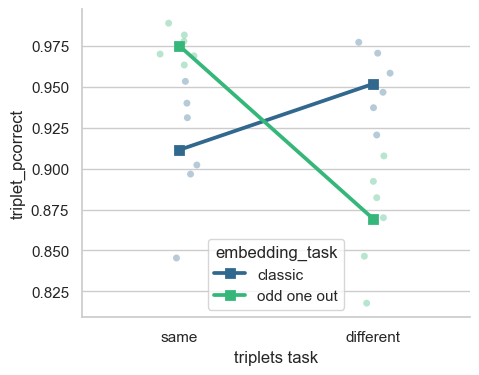

In [14]:
observer = 'O2'
dfplot = dfjoined[dfjoined['observer'] == observer]

plt.figure(figsize=(5, 4))
sns.pointplot(dfplot,  x='triplets task', y='triplet_pcorrect', hue='embedding_task', 
               dodge=False,  errorbar=None,
               marker='s', markersize=6, markeredgewidth=2, palette=sns.mpl_palette("viridis", 2), alpha=1, 
               zorder=2)

sns.stripplot(dfplot, x='triplets task', y='triplet_pcorrect', hue='embedding_task',
              dodge=False, legend=False, palette=sns.mpl_palette("viridis", 2), alpha=0.35, zorder=1)

sns.despine()

In [15]:
dfallobs = dfjoined.groupby(['image_set', 'embedding_task', 'triplets_task'])['triplet_pcorrect'].mean().reset_index()
dfallobs['triplets task'] = dfallobs['embedding_task'] == dfallobs['triplets_task']
dfallobs['triplets task'] = dfallobs['triplets task'].map({True: 'same', False: 'different'})
dfallobs['observer'] = 'All observers'
dfallobs

,image_set,embedding_task,triplets_task,triplet_pcorrect,triplets task,observer
0,action,classic,classic,0.861204,same,All observers
1,action,classic,odd one out,0.890027,different,All observers
2,action,odd one out,classic,0.805388,different,All observers
3,action,odd one out,odd one out,0.938489,same,All observers
4,greebles,classic,classic,0.818649,same,All observers
5,greebles,classic,odd one out,0.850026,different,All observers
6,greebles,odd one out,classic,0.765316,different,All observers
7,greebles,odd one out,odd one out,0.893091,same,All observers
8,taxonomic,classic,classic,0.884383,same,All observers
9,taxonomic,classic,odd one out,0.897270,different,All observers


In [16]:
# I am redoing this DF, so we have 1 data point per observer and not per imageset 
dfallobs = dfjoined.groupby(['observer', 'embedding_task', 'triplets_task'])['triplet_pcorrect'].mean().reset_index()
dfallobs['triplets task'] = dfallobs['embedding_task'] == dfallobs['triplets_task']
dfallobs['triplets task'] = dfallobs['triplets task'].map({True: 'same', False: 'different'})
dfallobs['reference_observer'] = dfallobs.observer
dfallobs['observer'] = 'All observers'
dfallobs

,observer,embedding_task,triplets_task,triplet_pcorrect,triplets task,reference_observer
0,All observers,classic,classic,0.865897,same,O1
1,All observers,classic,odd one out,0.880449,different,O1
2,All observers,odd one out,classic,0.806254,different,O1
3,All observers,odd one out,odd one out,0.942772,same,O1
4,All observers,classic,classic,0.911453,same,O2
5,All observers,classic,odd one out,0.951759,different,O2
6,All observers,odd one out,classic,0.869416,different,O2
7,All observers,odd one out,odd one out,0.975093,same,O2
8,All observers,classic,classic,0.802593,same,O3
9,All observers,classic,odd one out,0.814630,different,O3


In [17]:
dfplot = pd.concat((dfjoined, dfallobs))
dfplot

,observer,image_set,embedding_task,triplets_task,triplet_set,triplet_pcorrect,triplets task,reference_observer
0,O1,action,classic,classic,1,0.863333,same,NaN
1,O1,action,classic,classic,2,0.900000,same,NaN
2,O1,greebles,classic,classic,1,0.842047,same,NaN
3,O1,greebles,classic,classic,2,0.832222,same,NaN
4,O1,taxonomic,classic,classic,1,0.868889,same,NaN
...,...,...,...,...,...,...,...,...
15,All observers,NaN,odd one out,odd one out,NaN,0.925780,same,O4
16,All observers,NaN,classic,classic,NaN,0.901647,same,O5
17,All observers,NaN,classic,odd one out,NaN,0.940608,different,O5
18,All observers,NaN,odd one out,classic,NaN,0.806517,different,O5


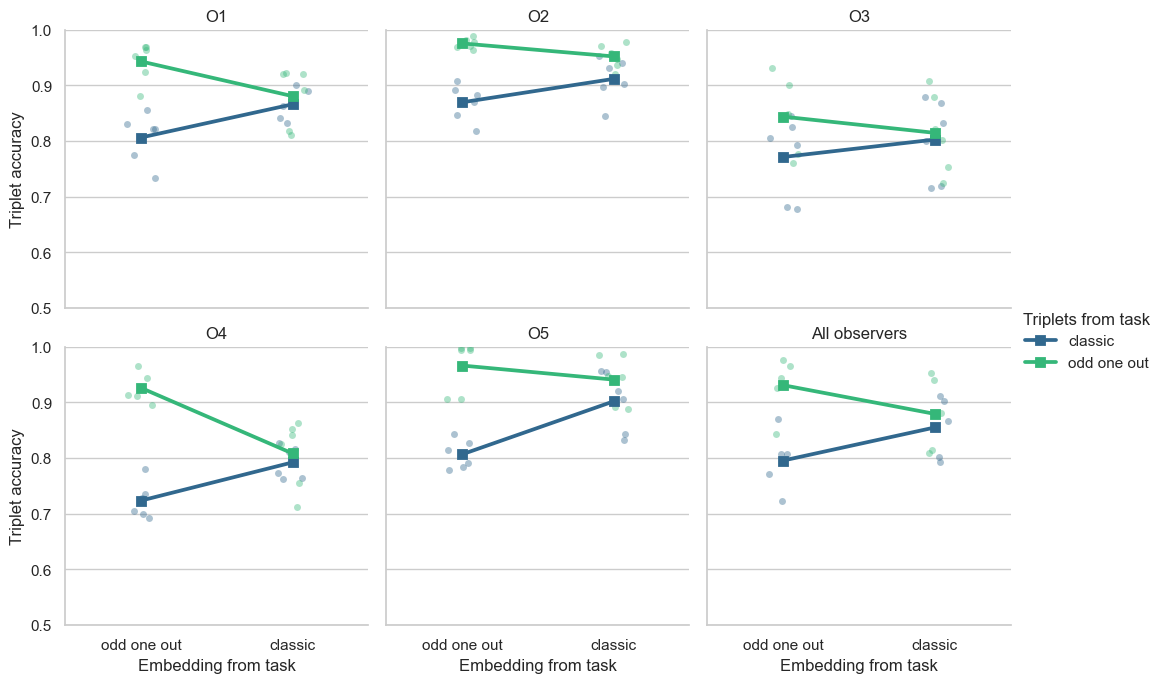

In [18]:
g = sns.FacetGrid(data=dfplot,  
                  #row='image_set', 
                  col = 'observer', hue='triplets_task', 
                  palette=sns.mpl_palette("viridis", 2), 
                  height=3.5, 
                  col_wrap=3)

g.map(sns.stripplot, 'embedding_task', 'triplet_pcorrect', order = ['odd one out', 'classic'],
      dodge=False, legend=False, alpha=0.4, zorder=1)

g.map(sns.pointplot, 'embedding_task', 'triplet_pcorrect', order = ['odd one out', 'classic'], errorbar=None,
      markersize=6, alpha=1, zorder=2, marker='s')
g.set_titles("{col_name}")
g.set(ylim=(0.5, 1))
g.set_xlabels("Embedding from task")
g.set_ylabels('Triplet accuracy')
g.add_legend(title="Triplets from task")
g.savefig('../plots/triplet_accuracy_from_embeddings/accuracy_by_swapping_task.pdf')

<Figure size 1200x600 with 0 Axes>

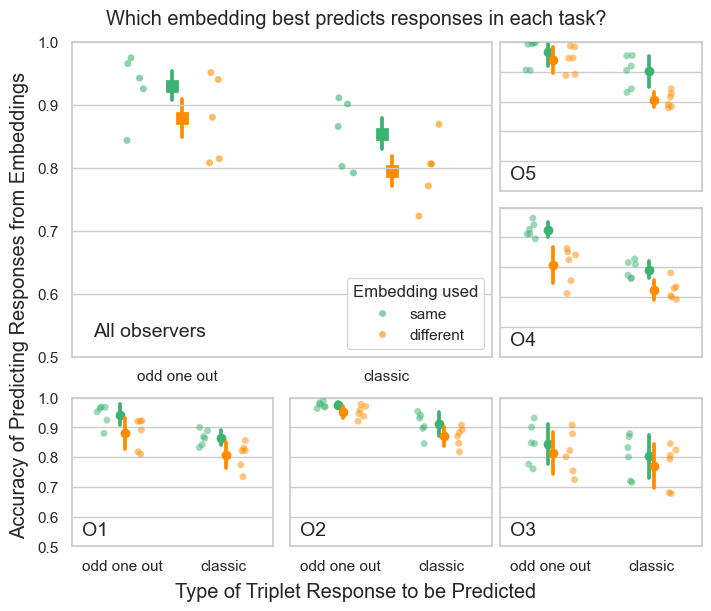

In [19]:

from matplotlib.gridspec import GridSpec

# Get unique observers
observers = dfplot["observer"].unique()


## set up figure and subplot grid
fig = plt.figure(layout="constrained", figsize=(12, 6))

gs = GridSpec(3, 6, figure=fig)

# Prepare layout: 1 large plot on top (the last one), 5 smaller plots below
fig = plt.figure(layout="constrained", figsize=(7, 6))

gs = GridSpec(3, 3, figure=fig)

ax5 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 2])
ax3 = fig.add_subplot(gs[2, 2])
ax2 = fig.add_subplot(gs[2, 1])
ax1 = fig.add_subplot(gs[2, 0])     

plotmapping = {'O1': ax1,
          'O2': ax2,
          'O3': ax3,
          'O4': ax4,
          'O5': ax5
          }
sns.set_style('whitegrid')
sns.set_context("notebook")

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }
palette_task = {'classic': (0.190631, 0.407061, 0.556089),
                'odd one out': (0.20803, 0.718701, 0.472873),
                'different': 'darkorange', 
                'same': 'mediumseagreen'
               }


# Plot the large subplot (last observer)
#ax_big       = fig.add_subplot(gs[1:4])  # Top row, span all 5 columns
ax_big  = fig.add_subplot(gs[0:2, 0:2])

sns.stripplot(data=dfallobs, x='triplets_task', y='triplet_pcorrect', hue='triplets task', 
              order=['odd one out', 'classic'], 
              alpha=0.6, palette=palette_task, ax=ax_big, legend=True,
              dodge = 0.2, size=5)
sns.pointplot(data=dfallobs, x='triplets_task', y='triplet_pcorrect', hue='triplets task',
              order=['odd one out', 'classic'], 
              errorbar='se', markers='s', markersize=7, 
              linestyles='none',
               markeredgewidth=2, dodge=0.05, ax=ax_big, palette=palette_task, legend=False, zorder=0)


        

ax_big.set_ylabel('')
ax_big.set_xlabel('')
ax_big.set_ylim([0.5, 1.0])
ax_big.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
#ax_big.set_yticklabels([ '0.6', '', '0.8', '', '1.0'], fontsize=10)
ax_big.annotate("All observers", xy=(0.05, 0.05), xycoords='axes fraction',
        xytext=(0.05, 0.05), textcoords='offset points',
        ha="left", va="bottom", fontsize=14, 
       )
ax_big.legend(title='Embedding used', title_fontsize=12, loc=4)

# Plot the small subplots
for i, observer in enumerate(observers[:-1]):  # First 5 observers
    ax = plotmapping[observer]
    
    df_small = dfplot[dfplot["observer"] == observer]

    sns.stripplot(data=df_small, x='triplets_task', y='triplet_pcorrect', hue='triplets task',
                  order=['odd one out', 'classic'], alpha=0.5, palette=palette_task, ax=ax,
                  dodge=0.2, legend=False, size=5)
    sns.pointplot(data=df_small, x='triplets_task', y='triplet_pcorrect', hue='triplets task',
                  order=['odd one out', 'classic'], errorbar='sd', markersize=5, linestyles='none',
                  dodge=0.05, ax=ax, palette=palette_task,
                  legend=False
                 )


                          
    #ax.set_title(observer)
    ax.set_ylim([0.5, 1.0])
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    #ax.set_yticklabels(['0.6', '', '0.8', '', '1.0'], fontsize=10)

    ax.annotate(observer, xy=(0.05, 0.05), xycoords='axes fraction',
            xytext=(0.05, 0.05), textcoords='offset points',
            ha="left", va="bottom", fontsize=14, 
           )

ax4.set_xticklabels([])
ax5.set_xticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])
ax4.set_yticklabels([])
ax5.set_yticklabels([])   
        
fig.supxlabel('Type of Triplet Response to be Predicted')
fig.supylabel('Accuracy of Predicting Responses from Embeddings')

fig.suptitle('Which embedding best predicts responses in each task?')

# Shared legend outside
# handles, labels = ax_big.get_legend_handles_labels()
# fig.legend(handles, labels, loc='upper center', ncol=2)

#plt.tight_layout(rect=[0, 0.05, 1, 1])  # Leave space for legend
plt.savefig("../plots/triplet_accuracy_from_embeddings/comparison_triplet_accuracy_from_same_diff_embeddings.pdf")

In [20]:
pivoted = (
    dfallobs
    .groupby(['embedding_task', 'reference_observer', 'triplets task'])['triplet_pcorrect'].mean()
)
pivoted

embedding_task  reference_observer  triplets task
classic         O1                  different        0.880449
                                    same             0.865897
                O2                  different        0.951759
                                    same             0.911453
                O3                  different        0.814630
                                    same             0.802593
                O4                  different        0.808093
                                    same             0.792137
                O5                  different        0.940608
                                    same             0.901647
odd one out     O1                  different        0.806254
                                    same             0.942772
                O2                  different        0.869416
                                    same             0.975093
                O3                  different        0.771296
                    

<Figure size 1200x600 with 0 Axes>

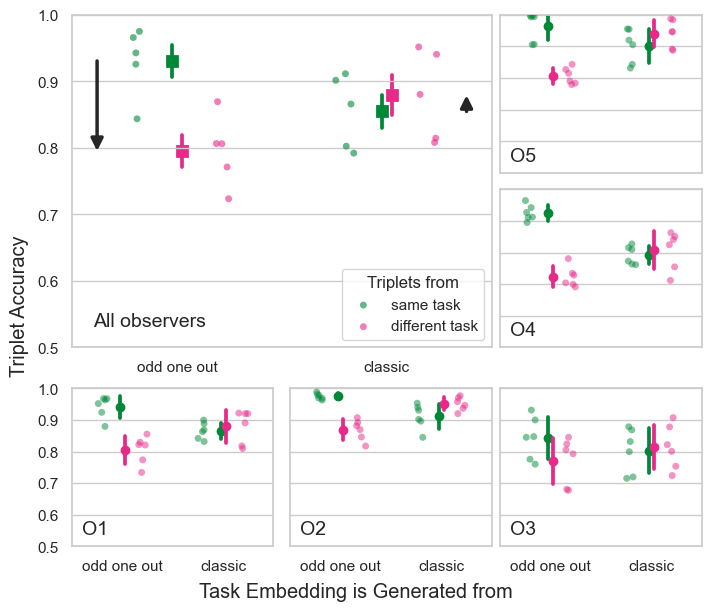

In [21]:

# the strip plots draw their jitter from numpy's global generator
np.random.seed(SEED)

# Get unique observers
observers = dfplot["observer"].unique()


## set up figure and subplot grid
fig = plt.figure(layout="constrained", figsize=(12, 6))

gs = GridSpec(3, 6, figure=fig)

# Prepare layout: 1 large plot on top (the last one), 5 smaller plots below
fig = plt.figure(layout="constrained", figsize=(7, 6))

gs = GridSpec(3, 3, figure=fig)

ax5 = fig.add_subplot(gs[0, 2])
ax4 = fig.add_subplot(gs[1, 2])
ax3 = fig.add_subplot(gs[2, 2])
ax2 = fig.add_subplot(gs[2, 1])
ax1 = fig.add_subplot(gs[2, 0])     

plotmapping = {'O1': ax1,
          'O2': ax2,
          'O3': ax3,
          'O4': ax4,
          'O5': ax5
          }
sns.set_style('whitegrid')
sns.set_context("notebook")

palette_imset = {'action': (0.4, 0.7607843137254902, 0.6470588235294118),
                 'greebles': (0.9882352941176471, 0.5529411764705883, 0.3843137254901961),
                 'taxonomic': (0.5529411764705883, 0.6274509803921569, 0.796078431372549),
                }
palette_task = {'classic': (0.190631, 0.407061, 0.556089),
                'odd one out': (0.20803, 0.718701, 0.472873),
                # saturated dark green and pink, distinct from the pastel green and orange
                # that code the image sets in the reliability figure
                'different': '#e7298a',
                'same': '#008837'
               }


# Plot the large subplot (last observer)
#ax_big       = fig.add_subplot(gs[1:4])  # Top row, span all 5 columns
ax_big  = fig.add_subplot(gs[0:2, 0:2])

sns.stripplot(data=dfallobs, x='embedding_task', y='triplet_pcorrect', hue='triplets task', 
              order=['odd one out', 'classic'], 
              alpha=0.6, palette=palette_task, ax=ax_big, legend=True,
              dodge = 0.2, size=5)
sns.pointplot(data=dfallobs, x='embedding_task', y='triplet_pcorrect', hue='triplets task',
              order=['odd one out', 'classic'], 
              errorbar='se', markers='s', markersize=7, 
              linestyles='none',
               markeredgewidth=2, dodge=0.05, ax=ax_big, palette=palette_task, legend=False, zorder=0)


        

ax_big.set_ylabel('')
ax_big.set_xlabel('')
ax_big.set_ylim([0.5, 1.0])
ax_big.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
#ax_big.set_yticklabels([ '0.6', '', '0.8', '', '1.0'], fontsize=10)
ax_big.annotate("All observers", xy=(0.05, 0.05), xycoords='axes fraction',
        xytext=(0.05, 0.05), textcoords='offset points',
        ha="left", va="bottom", fontsize=14, 
       )
ax_big.legend(['same task', 'different task'], title='Triplets from', title_fontsize=12, loc=4)

# arrows from the mean accuracy on triplets of the same task to that on triplets of the
# other task, left of the odd-one-out embeddings and right of the classic ones
mean_accuracy = dfallobs.groupby(['embedding_task', 'triplets task'])['triplet_pcorrect'].mean()
for embedding_task, x_arrow in [('odd one out', -0.38), ('classic', 1.38)]:
    ax_big.annotate('', xy=(x_arrow, mean_accuracy[(embedding_task, 'different')]),
                    xytext=(x_arrow, mean_accuracy[(embedding_task, 'same')]),
                    arrowprops=dict(arrowstyle='-|>', color='0.15', linewidth=2.5,
                                    mutation_scale=18, shrinkA=0, shrinkB=0))

# Plot the small subplots
for i, observer in enumerate(observers[:-1]):  # First 5 observers
    ax = plotmapping[observer]
    
    df_small = dfplot[dfplot["observer"] == observer]

    sns.stripplot(data=df_small, x='embedding_task', y='triplet_pcorrect', hue='triplets task',
                  order=['odd one out', 'classic'], alpha=0.5, palette=palette_task, ax=ax,
                  dodge=0.2, legend=False, size=5)
    sns.pointplot(data=df_small, x='embedding_task', y='triplet_pcorrect', hue='triplets task',
                  order=['odd one out', 'classic'], errorbar='sd', markersize=5, linestyles='none',
                  dodge=0.05, ax=ax, palette=palette_task,
                  legend=False
                 )


                          
    #ax.set_title(observer)
    ax.set_ylim([0.5, 1.0])
    ax.set_ylabel('')
    ax.set_xlabel('')
    ax.set_yticks([0.5, 0.6, 0.7, 0.8, 0.9, 1.0])
    #ax.set_yticklabels(['0.6', '', '0.8', '', '1.0'], fontsize=10)

    ax.annotate(observer, xy=(0.05, 0.05), xycoords='axes fraction',
            xytext=(0.05, 0.05), textcoords='offset points',
            ha="left", va="bottom", fontsize=14, 
           )

ax4.set_xticklabels([])
ax5.set_xticklabels([])
ax2.set_yticklabels([])
ax3.set_yticklabels([])
ax4.set_yticklabels([])
ax5.set_yticklabels([])   
        
fig.supxlabel('Task Embedding is Generated from')
fig.supylabel('Triplet Accuracy')


#fig.suptitle('Which responses does each embedding predict best?')

# Shared legend outside
# handles, labels = ax_big.get_legend_handles_labels()
# fig.legend(handles, labels, loc='upper center', ncol=2)

#plt.tight_layout(rect=[0, 0.05, 1, 1])  # Leave space for legend
plt.savefig("../plots/triplet_accuracy_from_embeddings/comparison_predicting_tasks_for_each_embeddings_with_arrows.pdf")

In [22]:
# get the number of the above plot, for the text
dfallobs.groupby(['embedding_task', 'triplets_task'])['triplet_pcorrect'].mean()

embedding_task  triplets_task
classic         classic          0.854745
                odd one out      0.879108
odd one out     classic          0.795399
                odd one out      0.930651
Name: triplet_pcorrect, dtype: float64

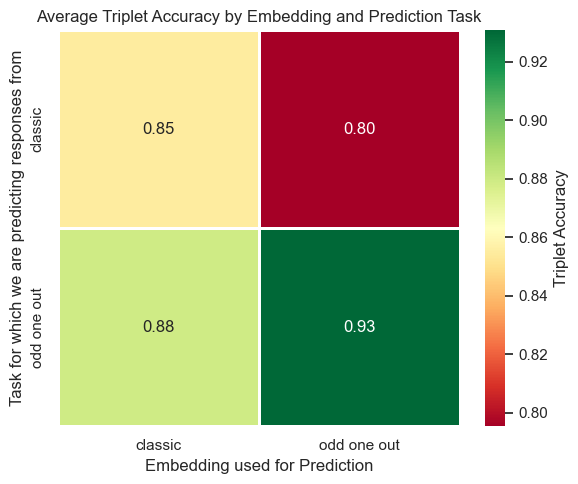

In [23]:
# Pivot to get averages
pivot = dfallobs.pivot_table(
    columns="embedding_task",
    index="triplets_task",
    values="triplet_pcorrect",
    aggfunc="mean"
)

# Plot heatmap
plt.figure(figsize=(6,5))
ax = sns.heatmap(pivot, annot=True, fmt=".2f", cmap="RdYlGn", cbar_kws={'label': 'Triplet Accuracy'}, linewidth=1)
ax.set_ylabel("Task for which we are predicting responses from")
ax.set_xlabel("Embedding used for Prediction")
plt.title("Average Triplet Accuracy by Embedding and Prediction Task")
plt.tight_layout()
plt.show()

## Now we take the embedding of one observer, and calculate triplet accuracy for the triplets coming from other observers

In [24]:
#observers = df['observer'].unique()
#observers

In [25]:
# data = []

# for j, row in df.iterrows():
    
#     observer = row['observer']
#     im_set = row['image_set']
#     task = row['task'] # 'odd one out' # odd one out

#     # get aggreaged embedding for this observer, imset and task
#     embedding_agg = get_agg_embedding_obs_task_imset(observer, im_set, task, df)

#     for other_obs in observers:

#         # skips if the observer is the same as from the embeddings
#         if other_obs == observer:
#             continue
            
#         # get triplets from sessions for this observer
#         sessions_triplets = triplet_df[(triplet_df['observer']==other_obs) & (triplet_df['image_set']==im_set) & (triplet_df['task']==task)]

#         # join all sessions from the observer
#         triplets = np.vstack(sessions_triplets['embedding_ready_triplets'].values)

#         # calculate triplet accuracy
#         score = calculate_triplet_correct(embedding = embedding_agg, triplets=triplets.astype(int))
    
#         data.append([observer, im_set, task, other_obs, score])
 


# df_scores_other_obs = pd.DataFrame(data, columns=['observer', 'image_set', 'embedding_task', 'other_observer', 'triplet_pcorrect']) 
# df_scores_other_obs

In [26]:
#df_scores_other_obs.groupby(['image_set', 'embedding_task'])['triplet_pcorrect'].mean()

In [27]:
#df_scores['other_observer'] = df_scores['observer']
#df_scores

In [28]:
# dfjoined_inter = pd.concat((df_scores, df_scores_other_obs))
# dfjoined_inter = dfjoined_inter[['observer', 'image_set', 'other_observer', 'embedding_task', 'triplet_pcorrect']]
# dfjoined_inter = dfjoined_inter.rename(columns={'embedding_task' : 'task'})
# dfjoined_inter

In [29]:
# dfjoined_inter['type'] = dfjoined_inter['observer'] == dfjoined_inter['other_observer']
# dfjoined_inter['type'] = dfjoined_inter['type'].map({True: 'intra', False: 'inter'})
# dfjoined_inter

In [30]:
# observer = 'O1'
# dfplot = dfjoined_inter[dfjoined_inter['observer'] == observer]

# plt.figure(figsize=(5, 4))
# sns.pointplot(dfplot,  x='type', y='triplet_pcorrect', hue='task', dodge=False,  errorbar=None,
#                marker="s", markersize=6, markeredgewidth=2, palette=sns.mpl_palette("viridis", 2), alpha=1, 
#                zorder=2)

# sns.stripplot(dfplot, x='type', y='triplet_pcorrect', hue='task',
#               dodge=False, legend=False, palette=sns.mpl_palette("viridis", 2), alpha=0.35, zorder=1)



# sns.despine()

In [31]:
# dfallobs = dfjoined_inter.groupby(['image_set', 'task', 'type'])['triplet_pcorrect'].mean().reset_index()
# dfallobs['observer'] = 'All observers'
# dfallobs

In [32]:
# dfplot = pd.concat((dfjoined_inter, dfallobs))

In [33]:
# g = sns.FacetGrid(data=dfplot,  
#                   #row='image_set', 
#                   col = 'observer', hue='task', palette=sns.mpl_palette("viridis", 2), 
#                   height=3.5, 
#                   col_wrap=3)

# g.map(sns.stripplot, 'type', 'triplet_pcorrect', order = ['intra', 'inter'],
#       dodge=False, legend=False, alpha=0.4, zorder=1)

# g.map(sns.pointplot, 'type', 'triplet_pcorrect', order = ['intra', 'inter'], errorbar=None,
#       markersize=6, alpha=1, zorder=2, marker='s')
# g.set_titles("{col_name}")
# g.set(ylim=(0.5, 1))
# g.set_xlabels('Type of comparison')
# g.set_ylabels('Triplet accuracy')
# g.add_legend(title='Task')
# g.savefig('../plots/triplet_accuracy_from_embeddings/accuracy_intra-inter-observer.pdf')